# [GPU 실습] 미세먼지 기사 제목 수천 개를 '뜻'으로 묶기
문장을 숫자 목록(임베딩)으로 바꾸면, 뜻이 비슷한 제목끼리 가까워져요. 가까운 것끼리 묶으면 **보도가 어떤 갈래로 나뉘는지** 한눈에 보여요.

준비: 1번 노트북에서 쓴 빅카인즈 파일(`NewsResult_*.xlsx`)을 같은 폴더에 · GPU가 없으면 CPU로도 돌아가요(느릴 뿐)

In [4]:
# ▶ 환경 준비 — Colab · VS Code 공통, 맨 처음 한 번 실행
import os, sys, platform, subprocess
IN_COLAB = 'google.colab' in sys.modules

def gpu_info():
    try:
        r = subprocess.run(['nvidia-smi', '--query-gpu=name,memory.total', '--format=csv,noheader'],
                           capture_output=True, text=True, timeout=10)
        return r.stdout.strip() or None
    except Exception:
        return None

GPU = gpu_info()
print('실행 위치:', 'Colab' if IN_COLAB else f'내 컴퓨터 ({platform.system()})')
print('GPU:', GPU or '없음 → CPU로 실행 (이 노트북은 CPU로도 충분해요)')

# (선택) pandas를 GPU로 — Colab GPU 런타임 또는 Linux/WSL에 cuDF가 있을 때만
USE_GPU_PANDAS = False          # True로 바꾸고 이 칸을 다시 실행
if USE_GPU_PANDAS and GPU:
    try:
        get_ipython().run_line_magic('load_ext', 'cudf.pandas')
        print('pandas → GPU(cuDF) 사용')
    except Exception as e:
        print('cuDF를 쓸 수 없어 일반 pandas로 실행:', type(e).__name__)

# 한글 글꼴: Colab은 나눔고딕 설치, 윈도우는 맑은 고딕, 맥은 애플고딕
import matplotlib.pyplot as plt
from matplotlib import font_manager as fm
if IN_COLAB:
    nanum = '/usr/share/fonts/truetype/nanum/NanumGothic.ttf'
    if not os.path.exists(nanum):
        subprocess.run('apt-get -qq install -y fonts-nanum > /dev/null', shell=True)
    fm.fontManager.addfont(nanum)
    plt.rcParams['font.family'] = 'NanumGothic'
elif platform.system() == 'Windows':
    plt.rcParams['font.family'] = 'Malgun Gothic'
elif platform.system() == 'Darwin':
    plt.rcParams['font.family'] = 'AppleGothic'
else:                                   # 리눅스·WSL: 설치된 한글 글꼴 찾기
    ko = [f.name for f in fm.fontManager.ttflist if 'Nanum' in f.name or 'CJK KR' in f.name]
    if ko: plt.rcParams['font.family'] = ko[0]
plt.rcParams['axes.unicode_minus'] = False
print('한글 글꼴:', plt.rcParams['font.family'])

실행 위치: 내 컴퓨터 (Windows)
GPU: NVIDIA GeForce RTX 5070 Laptop GPU, 8151 MiB
한글 글꼴: ['Malgun Gothic']


In [ ]:
# Co2:
    get_ipython().run_line_magic('pip', 'install -q sentence-transformers')

In [6]:
# ▶ VS Code용 설치 칸 — 처음 한 번만 실행 (torch가 GPU 버전인지 먼저 확인)
import sys, subprocess, importlib.util

def pip_install(*args):
    # sys.executable = 지금 커널(.venv)의 파이썬 → 그 환경에 설치
    subprocess.run([sys.executable, '-m', 'pip', 'install', '-q', *args], check=True)

IN_COLAB = 'google.colab' in sys.modules
need_restart = False

# ① torch: 없거나 CPU 버전이면 GPU용(CUDA 12.8)으로 설치
if not IN_COLAB:
    torch_ok = False
    if importlib.util.find_spec('torch') is not None:
        import torch
        torch_ok = torch.cuda.is_available()
    if not torch_ok:
        print('GPU용 torch를 설치합니다 (몇 GB라 5~10분 걸려요)...')
        pip_install('torch', '--index-url', 'https://download.pytorch.org/whl/cu128', '--force-reinstall')
        need_restart = True
    else:
        print('torch OK (GPU 사용 가능)')

# ② sentence-transformers: torch 다음에 설치해야 CPU 버전으로 바뀌지 않아요
if importlib.util.find_spec('sentence_transformers') is None:
    print('sentence-transformers를 설치합니다...')
    pip_install('sentence-transformers')
    print('sentence-transformers 설치 완료')
else:
    print('sentence-transformers 이미 설치됨')

if need_restart:
    print('\n⚠️ torch를 새로 설치했어요 → 위쪽 Restart 누르고 처음부터 다시 실행하세요')

torch OK (GPU 사용 가능)
sentence-transformers를 설치합니다...
sentence-transformers 설치 완료


In [7]:
import glob, time
import numpy as np, pandas as pd, torch
from sentence_transformers import SentenceTransformer

DEVICE = 'cuda' if torch.cuda.is_available() else 'cpu'
print('사용 장치:', DEVICE)

files = sorted(glob.glob('*NewsResult_*.xlsx'))
news = pd.concat([pd.read_excel(f) for f in files], ignore_index=True)
news = news.dropna(subset=['제목']).drop_duplicates(subset=['제목'])     # 같은 제목(통신사 전재) 빼기
titles = news['제목'].tolist()
print(len(titles), '개 제목')

W1111 09:03:43.498000 26068 Lib\site-packages\torch\distributed\elastic\multiprocessing\redirects.py:29] NOTE: Redirects are currently not supported in Windows or MacOs.


사용 장치: cuda


c:\workspace\ai-datajournalism-labs\.venv\Lib\site-packages\openpyxl\styles\stylesheet.py:237: UserWarning: Workbook contains no default style, apply openpyxl's default
  warn("Workbook contains no default style, apply openpyxl's default")


19400 개 제목


## 1. 한국어 문장 모델 불러오기 + CPU vs GPU 속도 비교

In [8]:
model = SentenceTransformer('jhgan/ko-sroberta-multitask', device=DEVICE)   # 처음 한 번 내려받기(약 400MB)

sample = titles[:500]
for dev in (['cpu', 'cuda'] if DEVICE == 'cuda' else ['cpu']):
    model.to(dev)
    t = time.time(); model.encode(sample, batch_size=64)
    print(f'{dev}: 제목 500개 → {time.time() - t:.1f}초')
model.to(DEVICE)

Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

cpu: 제목 500개 → 3.4초
cuda: 제목 500개 → 0.5초


SentenceTransformer(
  (0): Transformer({'transformer_task': 'feature-extraction', 'modality_config': {'text': {'method': 'forward', 'method_output_name': 'last_hidden_state'}}, 'module_output_name': 'token_embeddings', 'architecture': 'RobertaModel'})
  (1): Pooling({'embedding_dimension': 768, 'pooling_mode': 'mean', 'include_prompt': True})
)

## 2. 전체 제목을 숫자로 바꾸고, 비슷한 것끼리 묶기

In [9]:
emb = model.encode(titles, batch_size=128, show_progress_bar=True, normalize_embeddings=True)
print(emb.shape)      # (제목 수, 768) — 제목 하나가 숫자 768개

from sklearn.cluster import KMeans
K = 6                 # 묶음 수 — 4~8로 바꿔 보기
km = KMeans(n_clusters=K, n_init=10, random_state=42).fit(emb)
news['묶음'] = km.labels_

Batches:   0%|          | 0/152 [00:00<?, ?it/s]

(19400, 768)


## 3. 묶음마다 대표 제목 읽기 → 이름 붙이기 (사람의 일)

In [10]:
for k in range(K):
    idx = np.where(km.labels_ == k)[0]
    dist = np.linalg.norm(emb[idx] - km.cluster_centers_[k], axis=1)
    print(f'■ 묶음 {k} ({len(idx)}건)')
    for i in idx[dist.argsort()[:5]]:          # 묶음 한가운데에 가까운 제목 5개
        print('   ', titles[i])

■ 묶음 0 (4632건)
    이노디지털 "스마트 공기관리 플랫폼으로 탄소중립 시장 공략"
    [스케일업] 케이파워 [1] “친환경 산업용 보일러에 전기 생산 설비를 더합니다”
    [공기UP, 현장에서]'녹색전기' 만들며 공기 정화까지 진정한 친환경 발전
    세계 첫 수소혼소 발전기 상업가동 친환경에너지 기술 선도 [K브랜드 리포트]
    [High Collection] 업그레이드 된 항공모터로 지름 10㎛이하 미세먼지까지 싹싹 ~
■ 묶음 1 (3138건)
    [내일 날씨] 전국 흐리고 곳곳 '비' 낮에는 늦더위
    [내일날씨] 전국 곳곳에 비, 때이른 봄 더위 해소
    [내일 날씨] 전국 구름 많은 가운데 더위 지속... 곳곳에 소나기
    [내일날씨] 전국 흐리고 곳곳에서 비 소식 무더위는 계속
    오늘 날씨, 기상청 날씨예보 전국 날씨 흐리고 곳에따라 많은 비 주말에는 폭염 확대 기상특보
■ 묶음 2 (3001건)
    [날씨] 아침 쌀쌀, 낮 선선...차차 맑지만 미세먼지↑
    [내일날씨] 전국 맑고 한낮 쌀쌀, 큰 일교차 주의
    [내일날씨]전국 대체로 ‘맑음’, 해 지면 쌀쌀 큰 일교차 유의
    [날씨] 낮 동안 맑고 온화, 큰 일교차...밤사이 중서부 초미세먼지
    [내일 날씨] 전국 구름 많고 포근 일교차 미세먼지 '주의'
■ 묶음 3 (1660건)
    [날씨] 이맘때 겨울 추위...내일 중부 눈, 오후부터 찬 바람
    [날씨] 내일 아침 더 추워져 서해안 눈 살짝, 동해안 대기 건조
    [내일 날씨]"출근길 추워요" 아침 최저 영하 1도 오후엔 빗방울
    [내일 날씨] 전국 아침 기온 뚝 초겨울 추위 온다
    [내일날씨] 중부 아침 영하권 추위 일부 지역 눈 또는 비
■ 묶음 4 (3914건)
    광양시 '통합형 도시숲 가꾸기' 사업 착수...쾌적한 도시경관 창출
    평택 통북천 바람길숲, 올해 녹색도시 최우수・모범 도시숲 인증 ‘겹경사’
    iH(인천도시공사), 기

In [11]:
# 대표 제목을 읽고 이름을 붙이세요 (예: '예보·날씨', '건강', '중국발', '정책')
names = {0: '묶음0', 1: '묶음1', 2: '묶음2', 3: '묶음3', 4: '묶음4', 5: '묶음5'}
news['갈래'] = news['묶음'].map(names)

## 4. 기사용 차트 — 가장 큰 갈래 하나만 강조

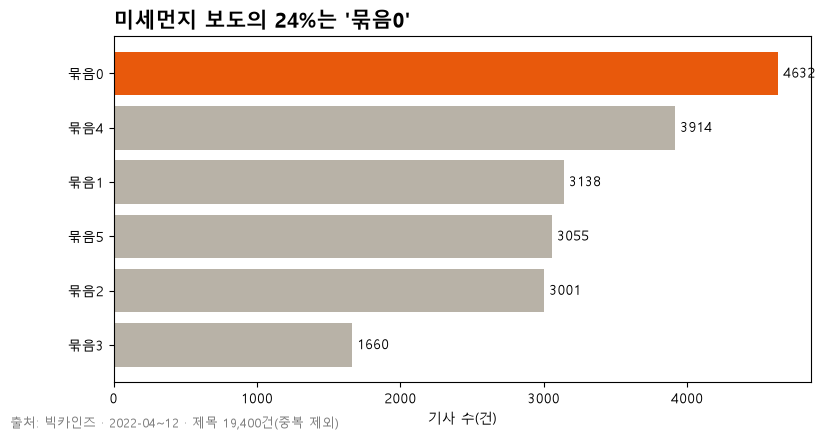

In [12]:
cnt = news['갈래'].value_counts().sort_values()
colors = ['#E8590C' if i == len(cnt) - 1 else '#B8B2A7' for i in range(len(cnt))]
fig, ax = plt.subplots(figsize=(9, 4.5))
bars = ax.barh(cnt.index, cnt.values, color=colors)
ax.bar_label(bars, padding=4)
ax.set_title(f"미세먼지 보도의 {cnt.values[-1] / cnt.sum():.0%}는 '{cnt.index[-1]}'", loc='left', fontsize=15, fontweight='bold')
fig.text(0.01, 0.01, f'출처: 빅카인즈 · 2022-04~12 · 제목 {cnt.sum():,}건(중복 제외)', fontsize=9, color='gray')
ax.set_xlabel('기사 수(건)'); plt.show()

### 읽을 때 주의
- 묶음은 컴퓨터가 **비슷한 정도**로 나눈 것이지 정답 분류가 아니에요. 이름은 사람이 대표 제목을 읽고 붙여요.
- K를 바꾸면 갈래도 바뀌어요. 기사에 쓸 때는 "제목을 뜻으로 묶어 보니"처럼 **방법을 밝혀요.**